In [25]:
import pandas as pd

df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [27]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [28]:
nulls = df.isna().any(axis=1)
df[nulls].sample(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1960,NaN,finance,self_employed,europe,74398.0,4,7,0.78,1
1502,paid_ads,NaN,employed,asia,41703.0,1,1,0.10,1
331,events,retail,NaN,europe,51461.0,2,7,0.63,0
3132,organic_search,manufacturing,self_employed,NaN,62956.0,0,1,0.27,0
2948,social_media,NaN,employed,asia,52717.0,1,2,0.28,1
3744,paid_ads,healthcare,student,NaN,NaN,4,7,0.49,1
3452,social_media,NaN,unemployed,europe,43803.0,2,4,0.45,1
2556,events,education,NaN,south_america,35770.0,2,3,0.39,1
448,paid_ads,NaN,employed,north_america,79186.0,3,5,0.50,1
968,NaN,technology,employed,north_america,91233.0,2,2,0.30,0


In [29]:
for col in df.columns:
  print(df[col].dtype)

str
str
str
str
float64
int64
int64
float64
int64


In [30]:
for col in df.columns:
  if df[col].dtype == 'str':
    df[col] = df[col].fillna('NA')
  else:
    df[col] = df[col].fillna(0.0)

In [31]:
df[nulls].sample(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
2643,social_media,technology,unemployed,asia,0.0,1,4,0.39,0
1998,social_media,technology,student,europe,0.0,0,1,0.28,1
3907,organic_search,healthcare,self_employed,NA,61847.0,2,3,0.32,1
1776,referral,education,NA,asia,41040.0,3,8,0.70,1
3981,social_media,education,unemployed,north_america,0.0,1,2,0.38,0
630,organic_search,NA,employed,asia,77524.0,2,3,0.48,1
4611,social_media,NA,employed,asia,79426.0,3,4,0.51,1
1541,organic_search,retail,unemployed,NA,12000.0,4,7,0.61,0
2296,paid_ads,education,NA,south_america,12000.0,0,2,0.23,0
832,events,NA,unemployed,north_america,37554.0,1,2,0.30,0


In [32]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
print(f"train data: {df_train.shape}")
print(f"val data: {df_val.shape}")
print(f"test data: {df_test.shape}")

train data: (3000, 9)
val data: (1000, 9)
test data: (1000, 9)


In [33]:
numeric_cols = df.select_dtypes(include='number')
catagorical_cols = df.select_dtypes(include='object')

/tmp/ipykernel_3018/2700427808.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catagorical_cols = df.select_dtypes(include='object')


In [34]:
from sklearn.metrics import roc_auc_score

scores = {}

for col in numeric_cols:
  pred = df_train[col]
  actual = df_train['converted']
  score = roc_auc_score(actual, pred)
  if score < 0.5:
    score = roc_auc_score(actual, -pred)
    col = f"-{col}"
  scores[col] = score

print(sorted(scores.items(), key= lambda i:i[1], reverse=True))

[('converted', 1.0), ('lead_score', 0.7882254810906102), ('interaction_count', 0.7649203047563227), ('number_of_courses_viewed', 0.7229894623989618), ('annual_income', 0.6081977776250831)]


In [35]:
from sklearn.feature_extraction import DictVectorizer

data_dict = df_train.to_dict(orient='records')
vec = DictVectorizer(sparse=False)
encoded_train_data = vec.fit_transform(data_dict)
encoded_df_train = pd.DataFrame(encoded_train_data, columns=vec.get_feature_names_out())
encoded_df_train.head()

,annual_income,converted,employment_status=NA,employment_status=employed,employment_status=self_employed,employment_status=student,employment_status=unemployed,industry=NA,industry=education,industry=finance,...,lead_source=paid_ads,lead_source=referral,lead_source=social_media,location=NA,location=africa,location=asia,location=europe,location=north_america,location=south_america,number_of_courses_viewed
0,80198.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,5.0
1,50548.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0
2,76300.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,80371.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0
4,73567.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0


In [36]:
y_train = encoded_df_train.pop('converted')
X_train = encoded_df_train
print(f"X shape: {X_train.shape}, y shape: {y_train.shape}")

X shape: (3000, 28), y shape: (3000,)


In [37]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [38]:
val_dict = df_val.to_dict(orient='records')
encoded_val_data = vec.transform(val_dict)
encoded_df_val = pd.DataFrame(encoded_val_data, columns=vec.get_feature_names_out())
encoded_df_val.head()

,annual_income,converted,employment_status=NA,employment_status=employed,employment_status=self_employed,employment_status=student,employment_status=unemployed,industry=NA,industry=education,industry=finance,...,lead_source=paid_ads,lead_source=referral,lead_source=social_media,location=NA,location=africa,location=asia,location=europe,location=north_america,location=south_america,number_of_courses_viewed
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,63357.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0
2,72351.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0
3,41501.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0
4,44817.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0


In [39]:
y_val = encoded_df_val.pop('converted')
X_val = encoded_df_val

print(f"X shape: {X_val.shape}, y shape: {y_val.shape}")

X shape: (1000, 28), y shape: (1000,)


In [40]:
from sklearn.metrics import roc_auc_score

y_pred = model.predict(X_val)
score = roc_auc_score(y_val, y_pred)
print(f"auc score: {round(score, 3)}")

auc score: 0.598


In [41]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, precision_recall_curve

thresholds = [t/100 for t in range(0, 100)]
prob = model.predict_proba(X_val)
pred_prob = prob[:,1]
scores = {}
precisions = []
recalls = []

for t in thresholds:
  y_pred = (pred_prob >= t).astype(float)
  precision = precision_score(y_val, y_pred, zero_division=0)
  recall = recall_score(y_val, y_pred, zero_division=0)
  scores[t] = {"precision":precision, "recall":recall}
  precisions.append(precision)
  recalls.append(recall)

print(scores)


{0.0: {'precision': 0.586, 'recall': 1.0}, 0.01: {'precision': 0.586, 'recall': 1.0}, 0.02: {'precision': 0.586, 'recall': 1.0}, 0.03: {'precision': 0.586, 'recall': 1.0}, 0.04: {'precision': 0.586, 'recall': 1.0}, 0.05: {'precision': 0.586, 'recall': 1.0}, 0.06: {'precision': 0.586, 'recall': 1.0}, 0.07: {'precision': 0.586, 'recall': 1.0}, 0.08: {'precision': 0.586, 'recall': 1.0}, 0.09: {'precision': 0.586, 'recall': 1.0}, 0.1: {'precision': 0.586, 'recall': 1.0}, 0.11: {'precision': 0.586, 'recall': 1.0}, 0.12: {'precision': 0.586, 'recall': 1.0}, 0.13: {'precision': 0.586, 'recall': 1.0}, 0.14: {'precision': 0.586, 'recall': 1.0}, 0.15: {'precision': 0.586, 'recall': 1.0}, 0.16: {'precision': 0.586, 'recall': 1.0}, 0.17: {'precision': 0.586, 'recall': 1.0}, 0.18: {'precision': 0.586, 'recall': 1.0}, 0.19: {'precision': 0.586, 'recall': 1.0}, 0.2: {'precision': 0.586, 'recall': 1.0}, 0.21: {'precision': 0.586, 'recall': 1.0}, 0.22: {'precision': 0.586, 'recall': 1.0}, 0.23: {'preci

In [42]:
valid_points = [(abs(p - r), i) for i, (p, r) in enumerate(zip(precisions, recalls)) if r > 0]
idx = valid_points.index(min(valid_points, key=lambda x:x[0]))
intersect = thresholds[idx]

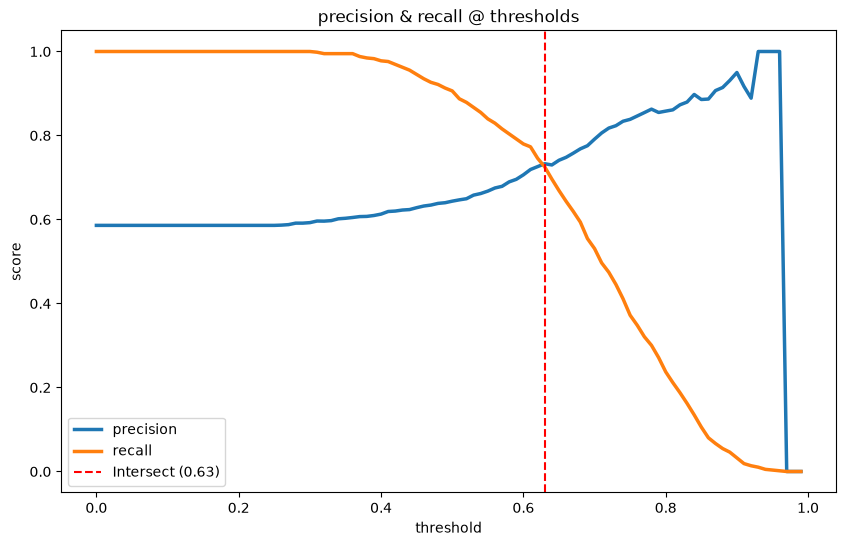

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.lineplot(x=thresholds, y=precisions, label='precision', linewidth=2.5)
sns.lineplot(x=thresholds, y=recalls, label='recall', linewidth=2.5)

plt.axvline(x=intersect, color='red', linestyle='--', label=f'Intersect ({intersect:.2f})')

plt.title('precision & recall @ thresholds')
plt.xlabel('threshold')
plt.ylabel('score')
plt.legend()
plt.show()

In [44]:
from sklearn.metrics import f1_score

f1_scores_sk = []
f1_scores = []

for t in thresholds:
  y_pred = (pred_prob >= t).astype(float)
  score_sk = f1_score(y_val, y_pred)
  f1_scores_sk.append(score_sk)
  precision = precision_score(y_val, y_pred, zero_division=0)
  recall = recall_score(y_val, y_pred, zero_division=0)
  score = 0 if (precision + recall)==0 else (2 * precision * recall) / (precision + recall)  
  f1_scores.append(score)

print(f1_scores_sk)
print(f1_scores)

[0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7389659520807061, 0.7394321766561515, 0.7403663929248263, 0.7431832593532023, 0.7431832593532023, 0.7441269841269841, 0.7466496490108487, 0.7455242966751918, 0.7464788732394366, 0.74983922829582, 0.7508048937540245, 0.752258064516129, 0.7519480519480519, 0.7513020833333334, 0.752449379490529, 0.7534516765285996, 0.7576158940397351, 0.7563249001331558, 0.7560321715817694, 0.7547169811320755, 0.7547683923705722, 0.7543014452856159, 0.753120665742025, 0.7541899441340782, 0.7524613220815752, 0.75

In [45]:
print(f"sklearn: maximal f1 {max(f1_scores)} is @ threshold {thresholds[f1_scores.index(max(f1_scores))]}")
print(f"manual: maximal f1 {max(f1_scores)} is @ threshold {thresholds[f1_scores.index(max(f1_scores))]}")

sklearn: maximal f1 0.7576158940397352 is @ threshold 0.41
manual: maximal f1 0.7576158940397352 is @ threshold 0.41


In [46]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1


In [60]:
from sklearn.model_selection import KFold, cross_val_score

df_copy = df_full_train.copy()
y_full_train = df_copy.pop('converted')
X_full_train = df_copy

kf = KFold(n_splits=5, shuffle=True, random_state=1)
auc_scores = []

for i, (train_idx, val_idx) in enumerate(kf.split(X_full_train, y_full_train)):
  X_train, y_train = X_full_train.iloc[train_idx], y_full_train.iloc[train_idx]
  X_val, y_val = X_full_train.iloc[val_idx], y_full_train.iloc[val_idx]
  vec = DictVectorizer(sparse=False)
  train_dict = X_train.to_dict(orient='records')
  val_dict = X_val.to_dict(orient='records')
  train_data = vec.fit_transform(train_dict)
  val_data = vec.transform(val_dict)
  df_train = pd.DataFrame(train_data, columns=vec.get_feature_names_out())
  df_val = pd.DataFrame(val_data, columns=vec.get_feature_names_out())
  model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
  model.fit(df_train, y_train)
  y_pred = model.predict(df_val)
  score = roc_auc_score(y_val, y_pred)
  auc_scores.append(score)

print(f"scores: {auc_scores}")
print(f"standard deviation: {np.std(auc_scores)}")

scores: [0.598298828438453, 0.5997560340281705, 0.6266218721037998, 0.6309138187696063, 0.628901405539479]
standard deviation: 0.014661887930321124


In [63]:
from numpy.typing import ArrayLike

def get_encoded_k_folds(X:ArrayLike, y:ArrayLike, k) -> tuple[list, list, list, list]:
  kf = KFold(n_splits=k, shuffle=True, random_state=1)
  train_fts, train_lbs, val_fts, val_lbs = [], [], [], []
  X = np.array(X)
  y = np.array(y)
  for i, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_train, y_train = X_full_train.iloc[train_idx], y_full_train.iloc[train_idx]
    X_val, y_val = X_full_train.iloc[val_idx], y_full_train.iloc[val_idx]
    vec = DictVectorizer(sparse=False)
    train_dict = X_train.to_dict(orient='records')
    val_dict = X_val.to_dict(orient='records')
    train_data = vec.fit_transform(train_dict)
    val_data = vec.transform(val_dict)
    df_train = pd.DataFrame(train_data, columns=vec.get_feature_names_out())
    df_val = pd.DataFrame(val_data, columns=vec.get_feature_names_out())
    train_fts.append(df_train)
    train_lbs.append(y_train)
    val_fts.append(df_val)
    val_lbs.append(y_val)
  return train_fts, train_lbs, val_fts, val_lbs

In [66]:
df_copy = df_full_train.copy()
y_full_train = df_copy.pop('converted')
X_full_train = df_copy

c_vals = [0.000001, 0.001, 1]
scores = {}

for c in c_vals:
  auc_scores = []
  train_fts, train_lbs, val_fts, val_lbs = get_encoded_k_folds(X_full_train, y_full_train, k=5)
  for X_train, y_train, X_val, y_val in zip(train_fts, train_lbs, val_fts, val_lbs):
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    score = roc_auc_score(y_val, y_pred)
    auc_scores.append(score)
  mean_auc = np.mean(auc_scores)
  std_auc = np.std(auc_scores)
  scores[c] = {"mean":round(mean_auc,3), "std":round(std_auc,3)}

print(scores)

{1e-06: {'mean': np.float64(0.504), 'std': np.float64(0.002)}, 0.001: {'mean': np.float64(0.608), 'std': np.float64(0.011)}, 1: {'mean': np.float64(0.617), 'std': np.float64(0.015)}}
